# Spatial Recurrence Lacunarity of DEM Slopes

This notebook applies the **normalized recurrence lacunarity (nRL)** of spatial recurrence plots (RPs) to the same SRTM and ASTER DEMs used in `example_analysis.ipynb`, and compares the result with the Fourier analysis there.

The method follows:

* Bielig, C., Braun, T., Palmero, M. S., Rheinwalt, A., and Marwan, N.: Recurrence lacunarity of spatial data, The European Physical Journal Special Topics, 2026. [https://doi.org/10.1140/epjs/s11734-026-02569-4](https://link.springer.com/article/10.1140/epjs/s11734-026-02569-4)

which builds on the recurrence lacunarity of:

* Braun, T., Unni, V. R., Sujith, R. I., Kurths, J., and Marwan, N.: Detection of dynamical regime transitions with lacunarity as a multiscale recurrence quantification measure, Nonlinear Dynamics, 104, 3955–3973, 2021. [https://doi.org/10.1007/s11071-021-06457-5](https://doi.org/10.1007/s11071-021-06457-5)

### The idea in brief

For an image $z$ the spatial RP is a **4D** binary array

$$R_{\mathbf{i},\mathbf{j}} = \Theta\left(\varepsilon - |z_\mathbf{i} - z_\mathbf{j}|\right), \qquad \mathbf{i} = (x_1, y_1),\ \mathbf{j} = (x_2, y_2)$$

that marks every pair of pixels with similar values. The threshold $\varepsilon$ is chosen so that a fixed fraction of all pairs recur (the recurrence rate, RR = 20% here, as in the paper).

The RP is then covered with non-overlapping 4D boxes of side $w$. Each box compares one $w \times w$ image patch with another, and its mass $M$ is the number of recurrent pixel pairs between them. The lacunarity $\Lambda(w) = \langle M^2 \rangle / \langle M \rangle^2$ is computed for both the RP and its inverse, and combined as

$$\mathrm{nRL}(w) = 2 - \left(\frac{1}{\Lambda(w)} + \frac{1}{\bar\Lambda(w)}\right)$$

which is ~0 when recurrences are spread evenly over all patch pairs (homogeneous RP) and ~1 when they cluster in some patch pairs and are missing from others (heterogeneous RP).

### How this relates to the Fourier analysis

Both methods look for characteristic length scales as departures from a power-law background. The power spectrum is the Fourier transform of the autocorrelation function, so it averages over position and assumes the field is statistically the same everywhere. The RP keeps *which* patches resemble *which*, so nRL measures how far the field departs from that translational invariance.

### Practical limits

An $n \times n$ image has an RP with $n^4$ entries: $10^{12}$ for the full 1000 × 1000 example DEMs. The code in `recurrence_lacunarity.py` never stores the RP. It builds it one band of patches at a time and reduces each band straight to box masses. Even so, we analyze a central **256 × 256 pixel (7.7 km)** crop, giving an RP of $4.3 \times 10^9$ pixel pairs per DEM.

# The Code

In [1]:
# import some python packages
import numpy as np
from scipy import stats
from osgeo import gdal
from matplotlib import pyplot as plt
import time
import warnings

from recurrence_lacunarity import recurrence_threshold, nrl, radial_spectrum

# ignore some warnings
warnings.filterwarnings('ignore')
gdal.UseExceptions()

# set figure size
plt.rcParams['figure.figsize'] = [15, 10]

In [2]:
# load in some helper functions
def loadDEM(dem):
    """
    Simple function to load a DEM as a numpy array and return the DEM
    pixel size.
    """
    ds = gdal.Open(dem)
    band = ds.GetRasterBand(1)
    gt = ds.GetGeoTransform()
    nan = band.GetNoDataValue()

    # read as array and set NaN
    el = band.ReadAsArray().astype(float)
    el[el == nan] = np.nan

    # get step size
    step = gt[1]

    return el, step

def slope_deg(z, step):
    """
    Slope in degrees from central differences.
    """
    gy, gx = np.gradient(z, step)
    return np.degrees(np.arctan(np.hypot(gx, gy)))

def rp_slices(z, eps):
    """
    Two 2D subsets of the 4D spatial RP (cf. Figs. 1 and 2 of Bielig et al.):
    the RP of the center image row (y1 = y2 = center), and the recurrences of
    the center pixel of the rightmost column with the whole image.
    """
    ny, nx = z.shape
    row = z[ny // 2]
    row_rp = np.abs(row[:, None] - row[None, :]) <= eps
    pixel_rp = np.abs(z - z[ny // 2, nx - 1]) <= eps
    return row_rp, pixel_rp

## 1. Sanity check on synthetic patterns

Before looking at the DEMs, we check the implementation on three synthetic 128 × 128 images like those in the paper: a periodic pattern (wavelength $\lambda$ = 16 px), the same pattern with white noise, and uniform white noise.

In [3]:
rng = np.random.default_rng(42)
n, lam = 128, 16
yy, xx = np.mgrid[:n, :n]
periodic = np.sin(2 * np.pi * xx / lam) * np.sin(2 * np.pi * yy / lam)

synthetic = {"Periodic ($\\lambda$ = 16 px)": periodic,
             "Periodic + noise": periodic + 0.5 * rng.standard_normal((n, n)),
             "White noise": rng.random((n, n))}

syn_ws = np.arange(2, 41)
syn_nrl = {}
for name, img in synthetic.items():
    t = time.time()
    syn_nrl[name], eps, rr = nrl(img, syn_ws)
    print("{:30s} eps = {:.3f}, RR = {:.3f} ({:.0f} s)".format(name, eps, rr, time.time() - t))

Periodic ($\lambda$ = 16 px)   eps = 0.200, RR = 0.203 (10 s)


Periodic + noise               eps = 0.258, RR = 0.200 (10 s)


White noise                    eps = 0.106, RR = 0.200 (10 s)


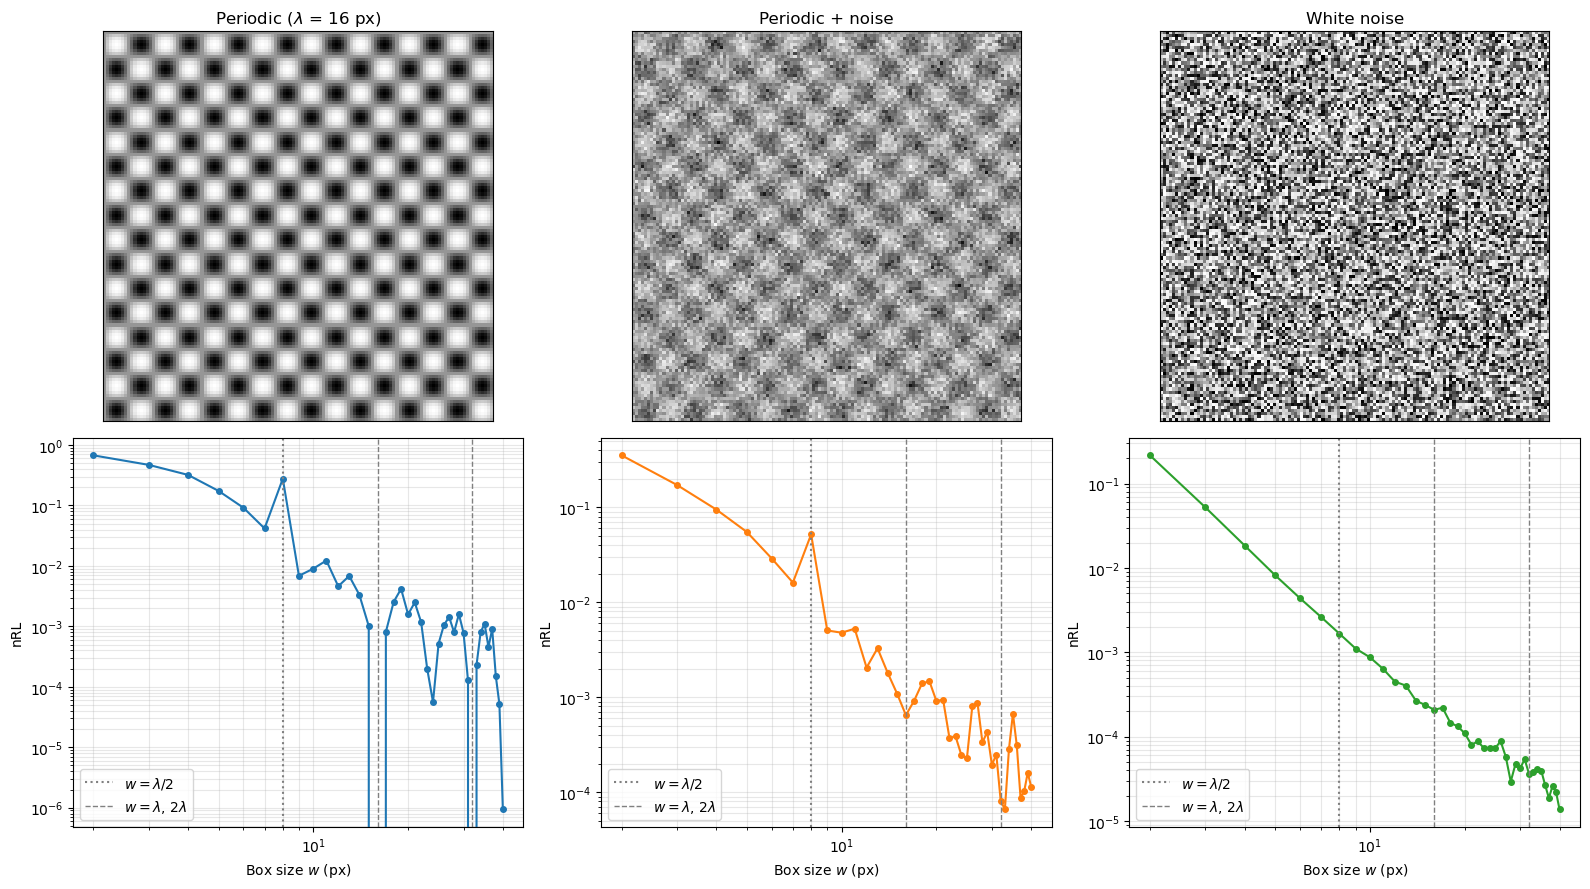

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for (name, img), ax_img, color in zip(synthetic.items(), axes[0], ['C0', 'C1', 'C2']):
    ax_img.imshow(img, cmap='Greys_r')
    ax_img.set_title(name)
    ax_img.set_xticks([]); ax_img.set_yticks([])

# nRL curves on log-log axes, where the power-law background is a straight line
for (name, c), ax, color in zip(syn_nrl.items(), axes[1], ['C0', 'C1', 'C2']):
    ax.loglog(syn_ws, c, 'o-', c=color, markersize=4)
    ax.axvline(lam / 2, c='gray', ls=':', lw=1.5, label='$w = \\lambda/2$')
    ax.axvline(lam, c='gray', ls='--', lw=1, label='$w = \\lambda$, $2\\lambda$')
    ax.axvline(2 * lam, c='gray', ls='--', lw=1)
    ax.set_xlabel('Box size $w$ (px)')
    ax.set_ylabel('nRL')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=10, loc='lower left')
plt.tight_layout()
plt.show()

The implementation reproduces the behavior described in the paper:

* **White noise** gives a straight power law with no extrema (cf. Fig. 3d of the paper). Every patch pair holds roughly the same share of recurrences, and the RP becomes homogeneous quickly as $w$ grows.
* **The periodic pattern** has a sharp **maximum at $w = \lambda/2$**. Boxes of that size each cover one crest or one trough, so a pair of patches either matches almost entirely or not at all, and the RP is very heterogeneous. At **$w = \lambda$ and $2\lambda$** every patch contains whole periods, so all patch pairs have the same mass and the nRL falls to (numerically) zero, dropping off the log axis. These are the "minima at the wavelength and its multiples" from the paper.
* **With noise added**, the same maximum and minima survive, only less pronounced.

A Fourier spectrum of the periodic pattern would show a single peak at $1/\lambda$. nRL encodes the same scale as a maximum at $\lambda/2$ and minima at multiples of $\lambda$.

## 2. The DEMs

As in the paper, which analyzes hillslope gradients, we work on **slope** rather than elevation. The same central 256 × 256 crop is taken from each DEM.

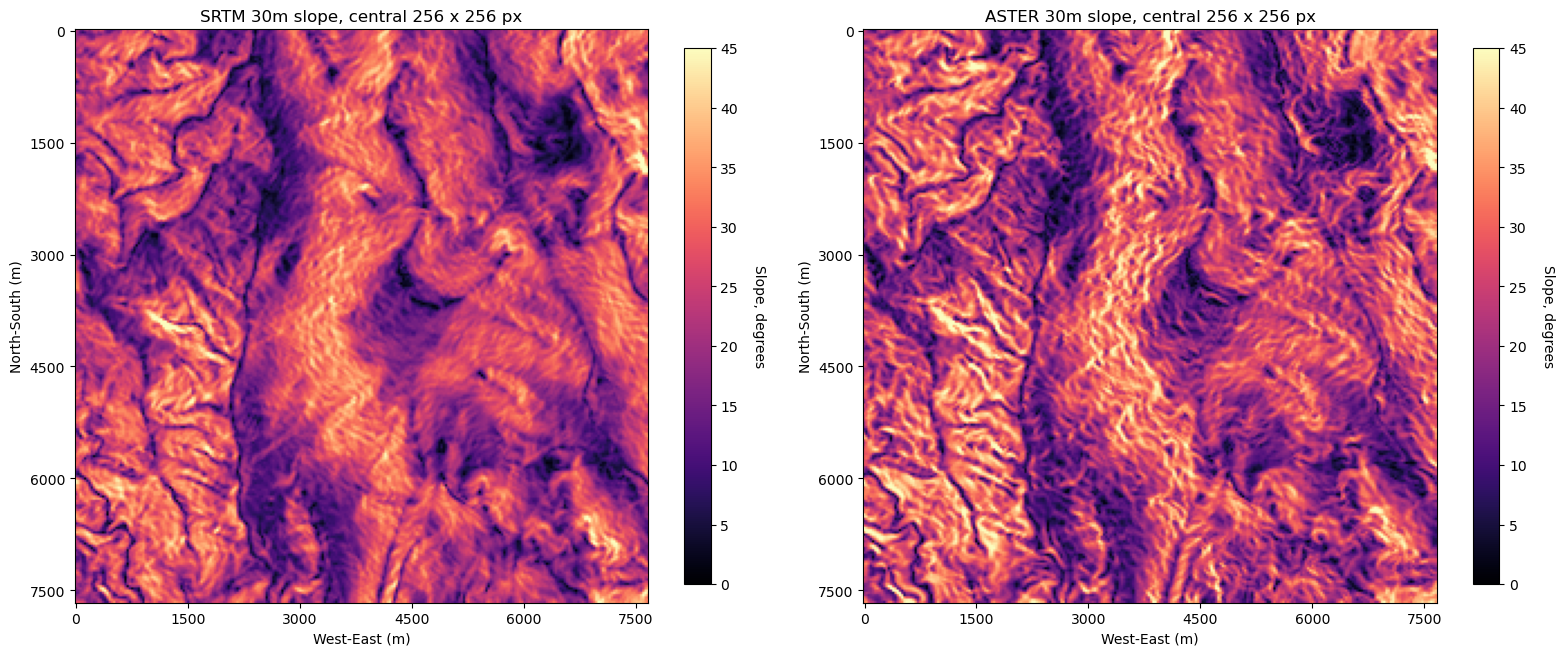

In [5]:
crop = 256
dems = {}
for name, fn in [("SRTM 30m", 'example_data/srtm30m_dem.tif'),
                 ("ASTER 30m", 'example_data/aster30m_dem.tif')]:
    z, step = loadDEM(fn)
    r0, c0 = (z.shape[0] - crop) // 2, (z.shape[1] - crop) // 2
    z = z[r0:r0 + crop, c0:c0 + crop]
    dems[name] = {"z": z, "slope": slope_deg(z, step), "step": step}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, d) in zip(axes, dems.items()):
    im = ax.imshow(d["slope"], cmap='magma', vmin=0, vmax=45)
    cbar = plt.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label('Slope, degrees', rotation=270, labelpad=20)
    ax.set_xticklabels(["{:.0f}".format(x * d["step"]) for x in ax.get_xticks()])
    ax.set_yticklabels(["{:.0f}".format(y * d["step"]) for y in ax.get_yticks()])
    ax.set_xlabel("West-East (m)")
    ax.set_ylabel("North-South (m)")
    ax.set_title(name + " slope, central {0} x {0} px".format(crop))
plt.tight_layout()
plt.show()

### Recurrence threshold and two slices through the 4D RP

The threshold is set separately for each DEM so that each RP has the same RR = 20%. The figure shows two of the axis-parallel 2D subsets described in Table 1 of the paper. On the left is the RP of the center image row, which compares every pixel of that row with every other. On the right are the recurrences of a single pixel (the center of the rightmost column) with the whole image.

SRTM 30m: eps = 2.96 degrees, RR = 0.200
ASTER 30m: eps = 3.35 degrees, RR = 0.200


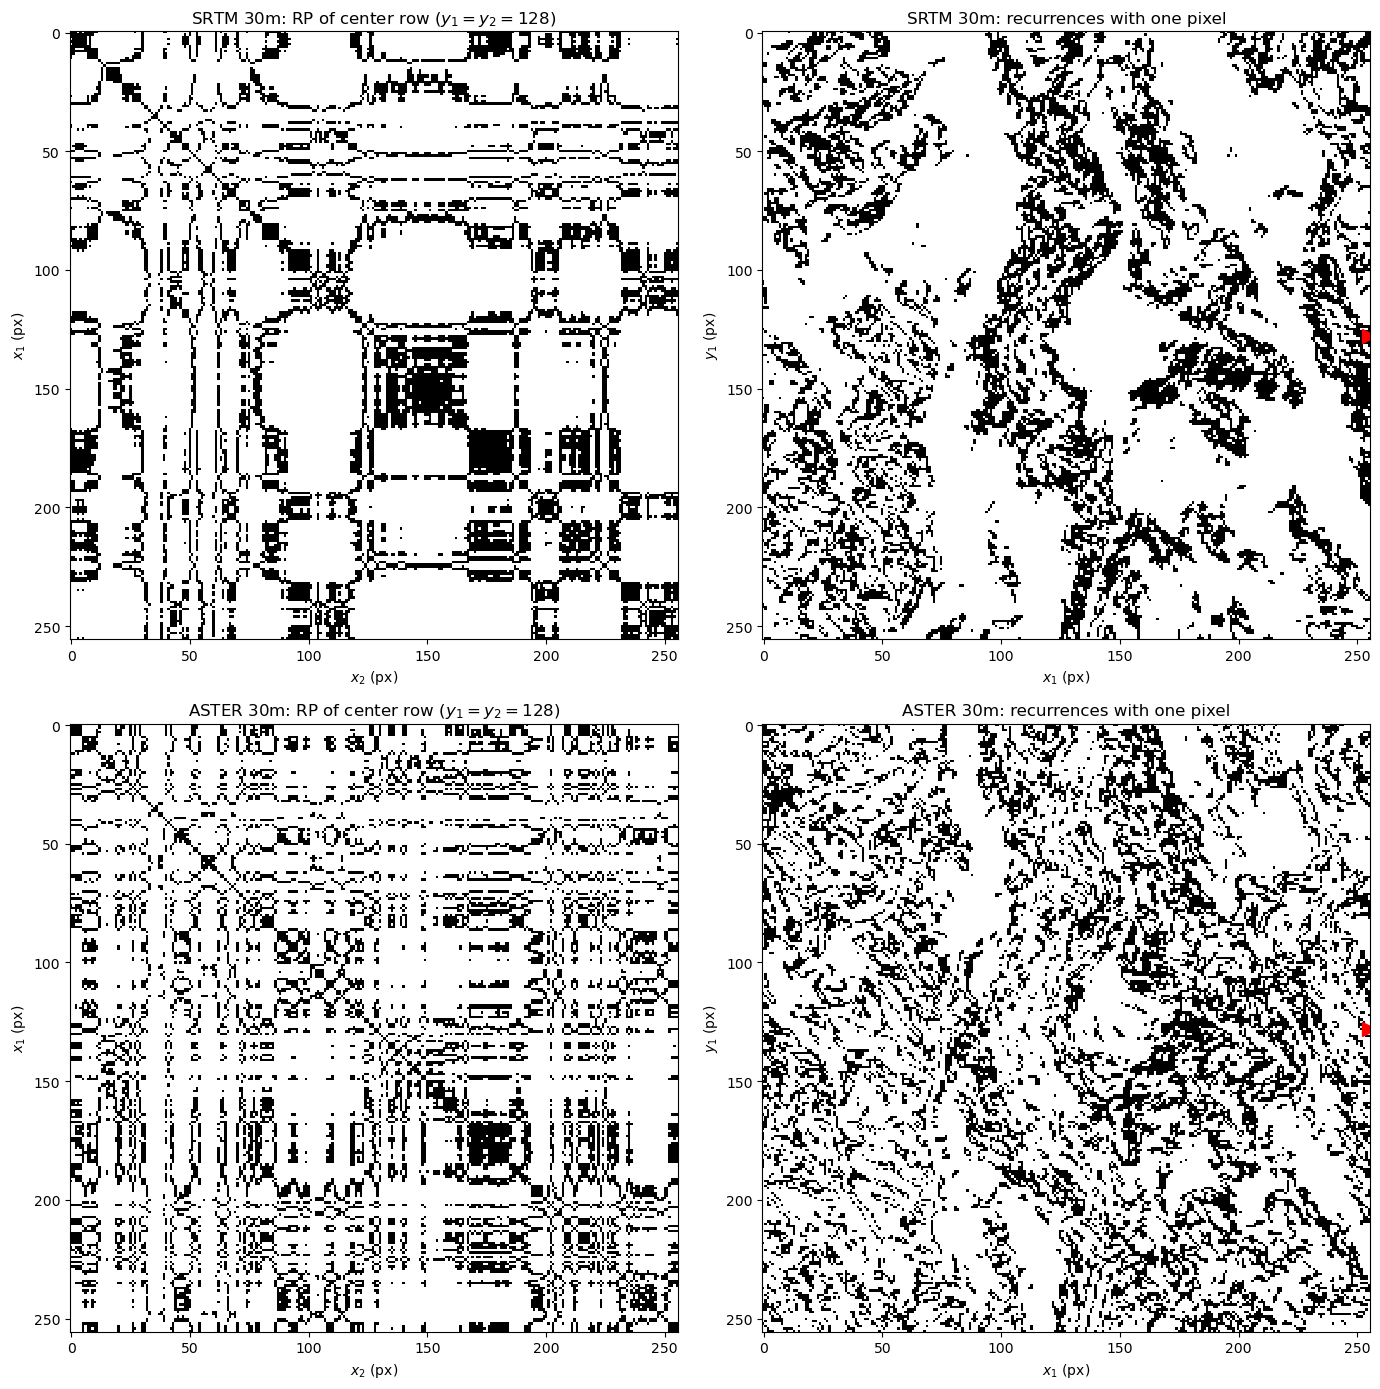

In [6]:
for name, d in dems.items():
    d["eps"], d["rr"] = recurrence_threshold(d["slope"], 0.2)
    print("{}: eps = {:.2f} degrees, RR = {:.3f}".format(name, d["eps"], d["rr"]))

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for ax_row, (name, d) in zip(axes, dems.items()):
    row_rp, pixel_rp = rp_slices(d["slope"], d["eps"])
    ax_row[0].imshow(row_rp, cmap='Greys', interpolation='nearest')
    ax_row[0].set_title("{}: RP of center row ($y_1 = y_2 = {}$)".format(name, crop // 2))
    ax_row[0].set_xlabel('$x_2$ (px)'); ax_row[0].set_ylabel('$x_1$ (px)')
    ax_row[1].imshow(pixel_rp, cmap='Greys', interpolation='nearest')
    ax_row[1].plot(crop - 1, crop // 2, 'r>', markersize=10)
    ax_row[1].set_title("{}: recurrences with one pixel".format(name))
    ax_row[1].set_xlabel('$x_1$ (px)'); ax_row[1].set_ylabel('$y_1$ (px)')
plt.tight_layout()
plt.show()

### nRL curves

We compute nRL for box sizes from 2 to 64 px (60 m to 1.9 km). As a reference we also include a **shuffled surrogate**: the SRTM slope pixels in random order. It has exactly the same value distribution, and therefore the same $\varepsilon$, but no spatial structure, which makes it the curve of pure noise.

*This cell takes a few minutes to run.*

In [7]:
ws = np.r_[np.arange(2, 17), np.arange(18, 65, 2)]

surrogate = rng.permutation(dems["SRTM 30m"]["slope"].ravel()).reshape(crop, crop)
runs = {name: d["slope"] for name, d in dems.items()}
runs["SRTM shuffled (surrogate)"] = surrogate

curves = {}
for name, img in runs.items():
    t = time.time()
    curves[name], eps, rr = nrl(img, ws)
    print("{:28s} eps = {:.2f}, RR = {:.3f} ({:.0f} s)".format(name, eps, rr, time.time() - t))

SRTM 30m                     eps = 2.96, RR = 0.200 (106 s)


ASTER 30m                    eps = 3.35, RR = 0.200 (107 s)


SRTM shuffled (surrogate)    eps = 2.96, RR = 0.200 (104 s)


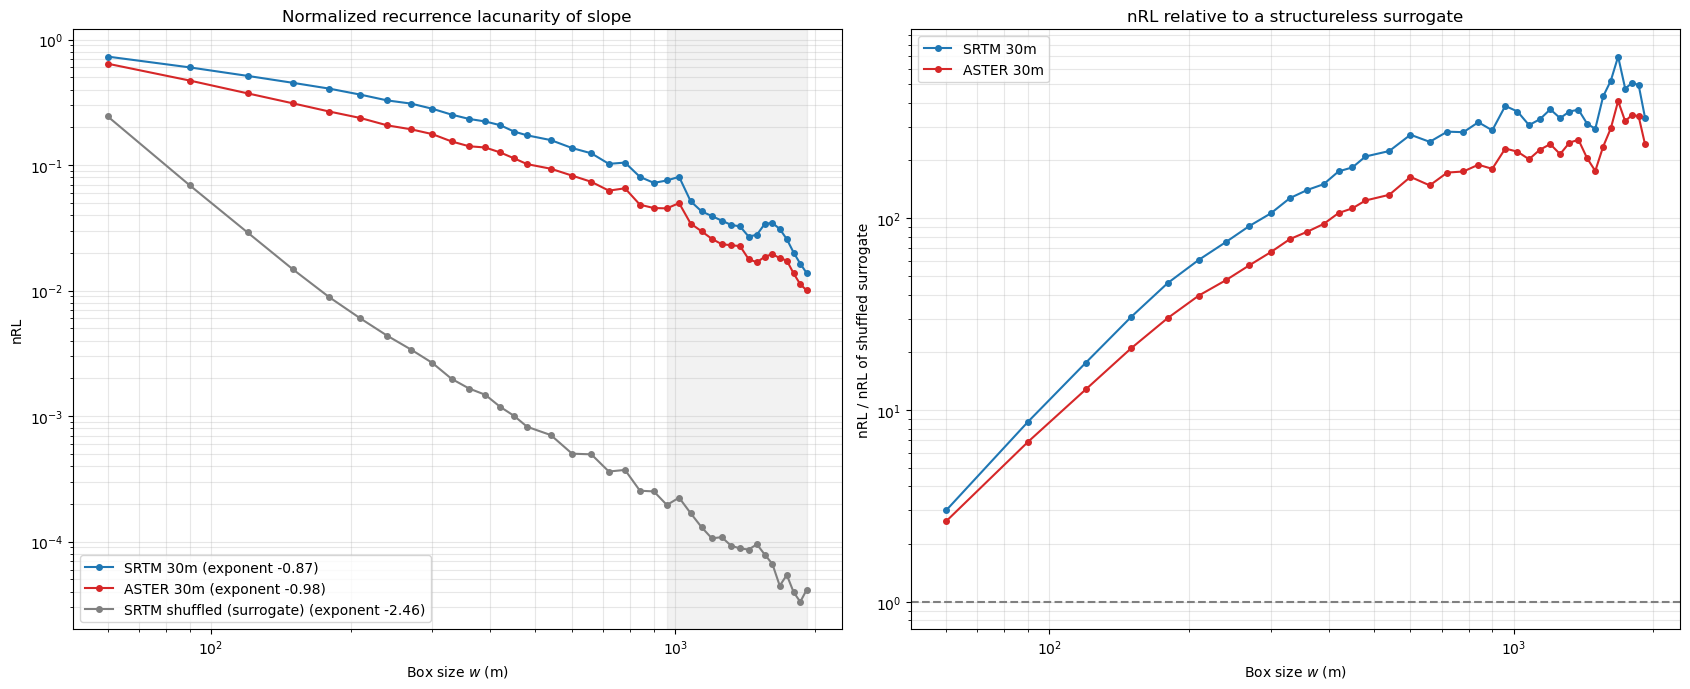

In [8]:
# power-law fits of nRL vs. w over the box sizes before edge effects set in
fit_range = ws <= 32
colors = {"SRTM 30m": 'C0', "ASTER 30m": 'C3', "SRTM shuffled (surrogate)": 'gray'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7))
for name, c in curves.items():
    slope_fit = np.polyfit(np.log10(ws[fit_range]), np.log10(c[fit_range]), 1)
    ax1.loglog(ws * 30, c, 'o-', c=colors[name], markersize=4,
               label="{} (exponent {:.2f})".format(name, slope_fit[0]))
ax1.axvspan(ws[fit_range].max() * 30, ws.max() * 30, color='gray', alpha=0.1)
ax1.set_xlabel('Box size $w$ (m)')
ax1.set_ylabel('nRL')
ax1.set_title('Normalized recurrence lacunarity of slope')
ax1.grid(True, which='both', alpha=0.3)
ax1.legend(fontsize=10)

# ratio to the surrogate shows how much spatial structure each DEM holds per scale
for name in dems:
    ax2.loglog(ws * 30, curves[name] / curves["SRTM shuffled (surrogate)"], 'o-',
                 c=colors[name], markersize=4, label=name)
ax2.axhline(1, c='gray', ls='--')
ax2.set_xlabel('Box size $w$ (m)')
ax2.set_ylabel('nRL / nRL of shuffled surrogate')
ax2.set_title('nRL relative to a structureless surrogate')
ax2.grid(True, which='both', alpha=0.3)
ax2.legend(fontsize=10)
plt.tight_layout()
plt.show()

## 3. Comparison with the Fourier spectrum of the same slope crops

For a like-for-like comparison, the 2D DFT from `example_analysis.ipynb` (plane detrend, Hann window, periodogram, radial collapse) is applied to the same slope crops rather than to elevation. Taking the gradient multiplies the elevation spectrum by roughly $k^2$, so these spectra are much flatter than the elevation spectra in the other notebook.

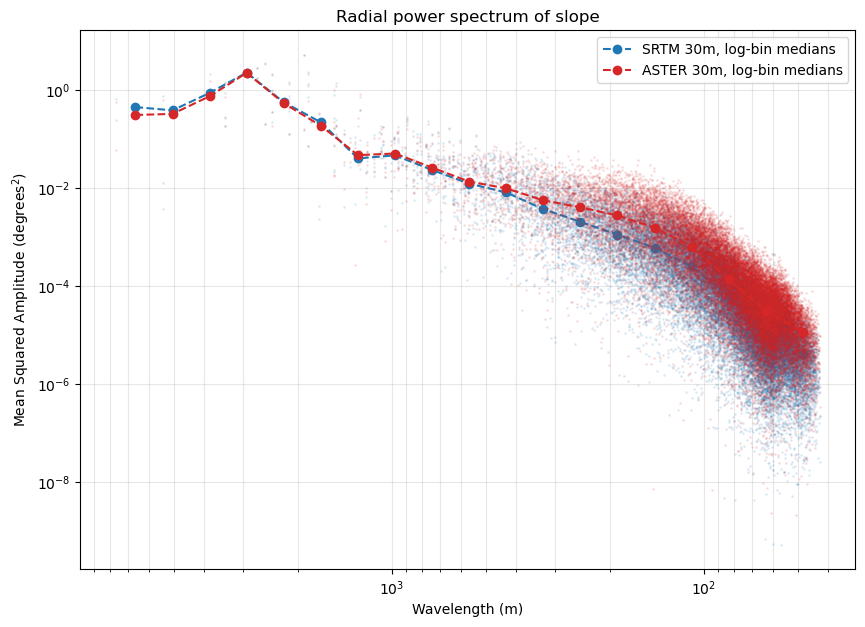

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
for name, d in dems.items():
    f1d, p1d = radial_spectrum(d["slope"], d["step"])
    f_bins = np.logspace(np.log10(f1d.min()), np.log10(f1d.max()), num=20)
    bin_med, edges, _ = stats.binned_statistic(f1d, p1d, statistic=np.nanmedian, bins=f_bins)
    bin_center = edges[:-1] + np.diff(edges) / 2
    ok = np.isfinite(bin_med)
    ax.loglog(1 / f1d, p1d, '.', c=colors[name], alpha=0.1, markersize=2, rasterized=True)
    ax.loglog(1 / bin_center[ok], bin_med[ok], 'o--', c=colors[name], label=name + ", log-bin medians")
ax.invert_xaxis()
ax.set_xlabel('Wavelength (m)')
ax.set_ylabel('Mean Squared Amplitude (degrees$^2$)')
ax.set_title('Radial power spectrum of slope')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=10)
plt.show()

# What do we see here?

**The RP slices.** The SRTM center-row RP is made of large solid blocks: long stretches of the row have similar slope (coherent hillslopes) and recur with each other. The ASTER RP shows the same overall layout broken up into a fine checkerboard, and its single-pixel recurrence map is speckled. The fine-scale noise visible in the hillshades of `example_analysis.ipynb` scatters recurrences across the RP.

**The nRL curves.** Both DEMs sit far above the shuffled surrogate at all box sizes. The ratio grows from a few at 60 m to hundreds at ~1 km, so most of the heterogeneity in these RPs comes from real spatial structure. ASTER, however, is **lower than SRTM at every scale**, with a slightly steeper power-law exponent. Its RP is more homogeneous, which puts it between SRTM and the structureless surrogate, as expected if noise is added to the same landscape.

This is the same signature that Bielig et al. read as *geomorphic* in the Mendocino catchments: lower nRL and a steeper curve meaning "finer-grained, more irregular" hillslope gradients. Here the two DEMs show the same landscape, and the difference comes entirely from **DEM noise**. Anyone comparing nRL across sites or sensors should therefore keep DEM quality fixed or account for it, which the paper itself lists as future work.

**No characteristic scale for the noise.** In the elevation spectrum, the ASTER noise is a distinct spike near 90 m (3 px). In nRL it shows up as a broadband offset rather than an extremum at $w \approx 3$. The slope spectrum above shows why the methods differ. The Fourier transform localizes the difference: ASTER carries excess power at wavelengths below ~300 m, while the two spectra are indistinguishable above ~1 km. nRL is not a band-pass measure. The box masses at every $w$ are still counts of *individual pixel* recurrences, so fine-scale noise that changes which pixels match also changes the masses at large $w$. The two methods are complementary: the spectrum says *at which wavelength* the DEMs differ, and nRL says *how much* the noise homogenizes the recurrence structure.

**Wiggles beyond ~1 km** (shaded) line up in all three curves, including the surrogate. With only ~8 × 8 patches per side at those box sizes they are edge effects of the 256 px crop, not landscape scales.

### Caveats

This is a single 256 × 256 crop per DEM, with the recurrence rate fixed at 20% and a single surrogate realization, so there is no significance testing. The paper's own caveats about sensitivity to RR also apply here.